In [1]:
import numpy as np
import matplotlib.pyplot as plt
from functools import reduce
from scipy import linalg as la


In [2]:
sigma_x = np.array([[0, 1], [1, 0]], dtype=complex)
sigma_y = np.array([[0, -1j], [1j, 0]], dtype=complex)
sigma_z = np.array([[1, 0], [0, -1]], dtype=complex)
I = np.eye(2, dtype=complex)

def sigma_op(op1, j, N, op2=None, k=None):
    """Operator op1 on qubit j, optionally op2 on qubit k, identity on the rest."""
    ops = [I] * N
    ops[j] = op1
    if op2 is not None:
        ops[k] = op2
    return reduce(np.kron, ops)

def H_isingall(N, delta, g):
    """
    Transverse-field Ising Hamiltonian H/hbar (units of angular frequency).

    N     : number of qubits
    delta : array (N,), effective fields Delta_j^I
    g     : array (N, N), Ising couplings g_jk (zero where qubits don't couple)
    Returns a 2^N x 2^N matrix.
    """
    H = np.zeros((2**N, 2**N), dtype=complex)
    for j in range(N):
        H -= delta[j] / 2 * sigma_op(sigma_z, j, N)
    for j in range(N):
        for k in range(j + 1, N):
            H += (g[j, k] + g[k, j]) * sigma_op(sigma_x, j, N) @ sigma_op(sigma_x, k, N)
    return H


*”In the rotating frame, the effective Ising fields are $\omega_{j,\text{Ising}} \equiv \Delta_j^I$, which are of order MHz, while the physical qubit frequencies are of order GHz, ensuring the RWA for the hardware coupling.”*

In [3]:
#system parameters for 2 qubits
N = 2
basis = np.eye(2**N, dtype=complex)   # basis[i] er |i>
E0 = basis[:,0] # |00>
E1 = basis[:,1] # |01>
E2 = basis[:,2] # |10>
E3 = basis[:,3] # |11>
E_values = np.array([E0, E1, E2, E3])
g = np.ones((N, N))*3*2*np.pi # 2pi * 3 MHz = 1,9 *10^7 rad/s = 19 rad/us
delta_j=np.ones((N))*3*2*np.pi # the interesting case is when delta_j and g_jk are close in value, so we set them equal for simplicity and sweep through a range of values one parameter at a time.

In [4]:
t = np.linspace(0, 0.5, 1000)
H = H_isingall(N, delta_j, g)
E, V = la.eigh(H)  # Eigenvalues and eigenvectors in the eigenbasis of H
# but the eigenvectors im interested in are [1,0,...,n] and [0,1,...,n] which are not the eigenvectors of H, so I need to express the initial state in the eigenbasis of H.
def coffs(V, En):
    """Compute the coefficients of the initial state in the eigenbasis of H."""
    return V.conj().T @ En  # coefficients of the initial state in the eigenbasis of H, the overlap of the initial state with the eigenvectors of H.
coffs_list = [coffs(V, En) for En in E_values]  # list of coefficients for each initial state

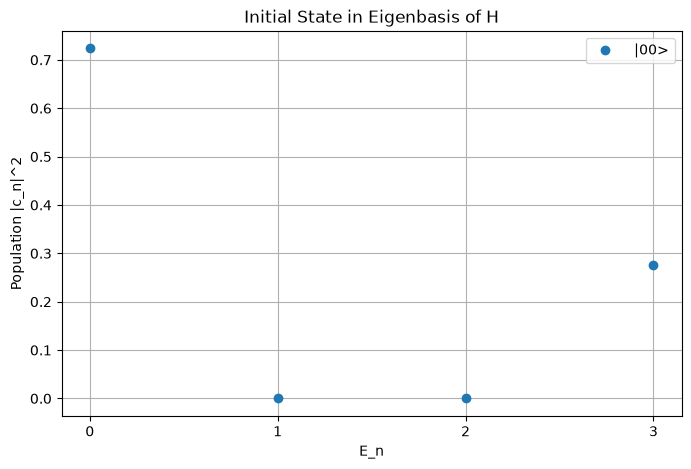

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(abs(coffs_list[0])**2, 'o', label=' |00>')
#plt.plot(abs(coffs_list[1])**2, 'o', label=' |01>')
#plt.plot(abs(coffs_list[2])**2, 'o', label=' |10>')
#plt.plot(abs(coffs_list[3])**2, 'o', label=' |11>')
plt.xticks(range(2**N))
plt.xlabel('E_n')
plt.ylabel('Population |c_n|^2')
plt.title('Initial State in Eigenbasis of H')
plt.legend(loc='upper right')
plt.grid()

In [6]:
def time_evolv(coffs, E, V, t):
    """Time evolution of the state given coefficients in the eigenbasis and eigenvalues."""
    psi_t= []
    for ti in t:
        w = coffs * np.exp(-1j * E * ti)
        psi_t.append(np.sum(w*V, axis=1))
    return np.array(psi_t)

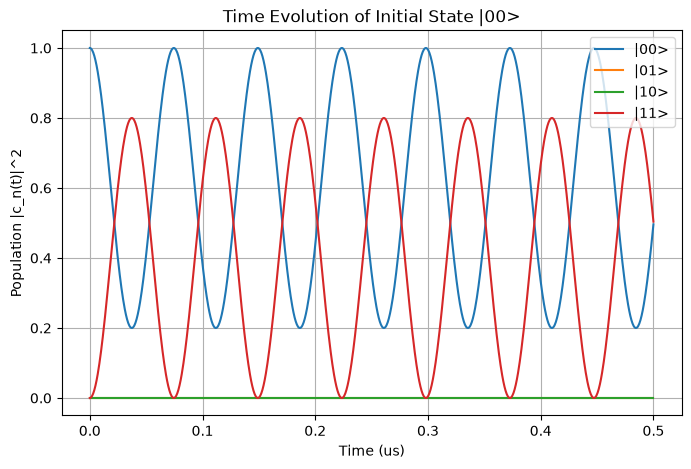

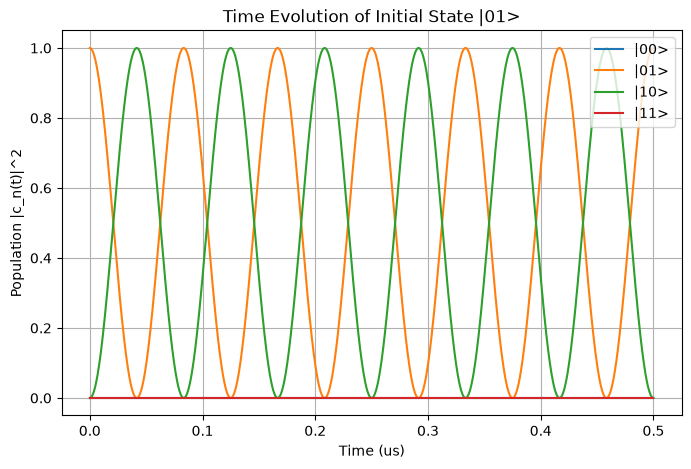

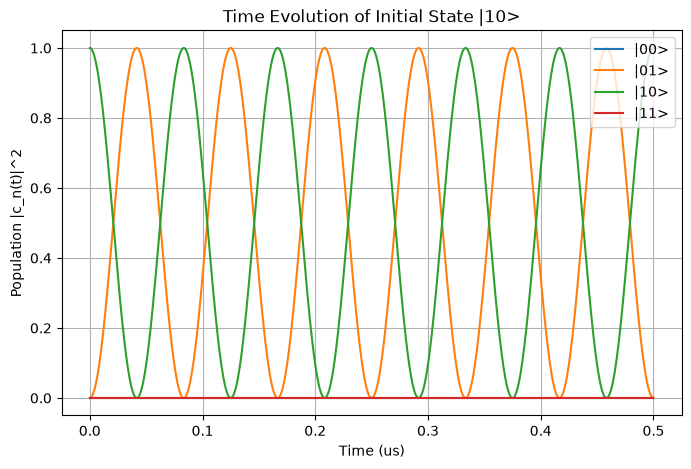

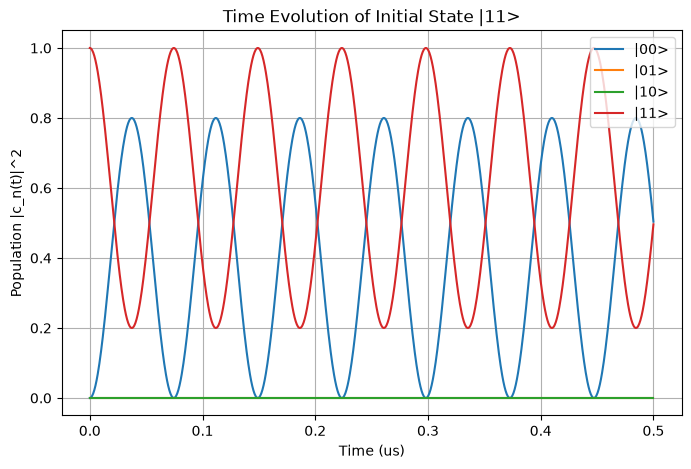

In [7]:
for i, En in enumerate(E_values):
    psi_t = time_evolv(coffs_list[i], E, V, t) #psi_0(t) = sum_n0 c_n0 exp(-i E_n t) |E_n>
    plt.figure(figsize=(8, 5))
    for j in range(2**N):
        plt.plot(t, abs(psi_t[:, j])**2, label=f'|{j:02b}>')
    plt.xlabel('Time (us)')
    plt.ylabel('Population |c_n(t)|^2')
    plt.title(f'Time Evolution of Initial State |{i:02b}>')
    plt.legend(loc='upper right')
    plt.grid()

In [8]:
#shows that 00 couples to 11 and 01 couples to 10, which is what I expect from the Ising Hamiltonian.

In [9]:
c=3*2*np.pi # coupling strength in rad/us
g = np.ones((N, N))*c # 2pi * 3 MHz = 1,9 *10^7 rad/s = 19 rad/us
delta_j_values=np.linspace(0.25*c,5*c,5)

In [10]:
def H_XY(N, delta, g):
    H = np.zeros((2**N, 2**N), dtype=complex)
    for j in range(N):
        H -= delta[j] /2 * sigma_op(sigma_z, j, N)
    for j in range(N):
        for k in range(j + 1, N):
            H += (g[j, k]) * (sigma_op(sigma_x, j, N) @ sigma_op(sigma_x, k, N) + sigma_op(sigma_y, j, N) @ sigma_op(sigma_y, k, N))
    return H
def H_AXY(N, delta, g):
    return sigma_op(sigma_x,0,N)@H_XY(N, delta, g)@sigma_op(sigma_x,0,N)

In [11]:
H_xy= H_XY(N, delta_j, g)

In [12]:
def U_trotter(H, tau, n, N):
    """First-order Trotter: (U_axy U_xy)^n for one XY + A-XY pair."""
    X1 = sigma_op(sigma_x, 0, N)
    U_xy  = la.expm(-1j * H * tau)
    U_axy = la.expm(-1j * (X1 @ H @ X1) * tau)
    return np.linalg.matrix_power(U_axy @ U_xy, n @ U_axy @ U_xy)

In [17]:
n=5
np.arange(n)

array([0, 1, 2, 3, 4])